# Supplementary · L2 search for the deep ConvNCF (MovieLens-1M)

Supports thesis §7.1 ("ConvNCF architecture choice"). The same output-layer L2 search, applied to the
deep 6-layer ConvNCF (32 filters per layer) from the original paper. MF is pretrained on the full
training set and the search runs on 40 % of it. The thesis reports that these deep configurations were
unstable, which is why the final experiments use the shallow variant.

In [ ]:
# Folder containing ml-1m.ratings.dat and yelp.rating (see data/README.md).
# On Kaggle, point this at the attached dataset, e.g. "/kaggle/input/<dataset-name>".
DATA_DIR = "../../data"

Utils, evaluation, data preprocessing, BPR, BPR sequence

In [ ]:

import random, math
from functools import lru_cache
from collections import defaultdict
#HR (hit ratio)
def HR(ranked_predicted_list, true_test_item, number_of_rec_items):
    top_rec_items = ranked_predicted_list[:number_of_rec_items]
    item_ids = [item_id for item_id, _ in top_rec_items]
    if true_test_item in item_ids:
        return 1.0
    else:
        return 0.0
    
#Normalized Discounted Cumulative Gain (NDCG) 


def NDCG(ranked_predicted_list, true_test_item, number_of_rec_items):
    top_rec_items = ranked_predicted_list[:number_of_rec_items]
    item_ids = [item_id for item_id, _ in top_rec_items]
    for rank, item_id in enumerate(item_ids):
        if item_id == true_test_item:
            return 1.0/math.log2((rank+1) +1)
    return 0



#Get the predictions


#Evaluation using HR
def eval_hr_ndcg(
    interaction_matrix, interaction_array, test_df, model,
    number_of_rec_items, max_test_size, neg_sample_size
):
    # Build pivot mappings
    user_index_list = interaction_matrix.index.tolist()
    item_index_list = interaction_matrix.columns.tolist()

    user2pivot = {uid: idx for idx, uid in enumerate(user_index_list)}
    item2pivot = {iid: idx for idx, iid in enumerate(item_index_list)}

    # For each user (by pivot index), record the set of interacted item pivot indices
    user_item_dict = defaultdict(set)
    n_users, n_items = interaction_array.shape
    for u in range(n_users):
        user_item_dict[u] = set(np.where(interaction_array[u] == 1)[0])

    all_items = list(range(n_items))

    users = test_df['user_id'].values
    items = test_df['item_id'].values

    num_hits = 0.0
    num_test = 0.0
    sum_ndcg = 0.0

    for df_user, df_item in zip(users, items):
        if (df_user not in user2pivot) or (df_item not in item2pivot):
            continue

        user_idx = user2pivot[df_user]
        item_idx = item2pivot[df_item]

        items_interacted = user_item_dict[user_idx]
        possible_neg = list(set(all_items) - items_interacted)

        if len(possible_neg) == 0:
            # nothing to sample for this user; skip
            continue

        k = min(neg_sample_size, len(possible_neg))
        negative_sample = random.sample(possible_neg, k)

        test_sample_per_user = negative_sample + [item_idx]

        array_of_users = np.full(len(test_sample_per_user), user_idx, dtype='int32')
        array_of_items = np.array(test_sample_per_user, dtype='int32')

        predictions = model.predict([array_of_users, array_of_items], verbose=0).flatten()
        ranked_predicted_list = sorted(zip(test_sample_per_user, predictions),
                                       key=lambda x: x[1], reverse=True)

        hit = HR(ranked_predicted_list, item_idx, number_of_rec_items=number_of_rec_items)
        ndcg_val = NDCG(ranked_predicted_list, item_idx, number_of_rec_items)

        num_hits += hit
        sum_ndcg += ndcg_val
        num_test += 1

        

        if num_test >= max_test_size:
            break

    if num_test == 0:
        average_num_hits = 0.0
        ndcg_k = 0.0
    else:
        average_num_hits = num_hits / num_test
        ndcg_k = sum_ndcg / num_test

    
    return average_num_hits, ndcg_k


import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder

df = pd.read_csv(f"{DATA_DIR}/ml-1m.ratings.dat", sep="::", engine="python",
                 names=["user_id", "item_id", "rating", "timestamp"])
print("Original data:")
print(df.head())

#Check that every user has >=20 rankings

user_counts = df.groupby("user_id").size()
print("Minimum number of ratings per user:", user_counts.min())

# Sort the data by user, then by timestamp (ascending)
df = df.sort_values(['user_id', 'timestamp'])

# We will collect train rows and test rows in separate lists
train_list = []
test_list  = []

# Group by each user
for user_id, group in df.groupby('user_id'):
    # Convert group to list (or keep as DF if you like)
    user_history = group.values  # or group.to_numpy()

    # The last row of this user’s history is the "most recent" (test instance)
    test_interaction = user_history[-1]
    
    # All preceding rows are training data
    train_interactions = user_history[:-1]

    # Add them to our overall lists
    for row in train_interactions:
        train_list.append(row)
    test_list.append(test_interaction)

# Convert lists back to DataFrame
train_df = pd.DataFrame(train_list, columns=df.columns)
test_df  = pd.DataFrame(test_list,  columns=df.columns)
train_df = train_df.sort_values(['user_id', 'timestamp'])

val_df = train_df.groupby('user_id').tail(1).copy()   # 1 row per user
train_df_cv = train_df.drop(val_df.index).copy()

train_df = train_df_cv
print("Training size:", len(train_df))
print("Testing size: ", len(test_df))
# --- label-encode user/item to 0..n-1 (fit on TRAIN_CV + VAL + TEST) ---
ue, ie = LabelEncoder(), LabelEncoder()

all_ids = pd.concat([
    train_df[['user_id','item_id']],   # TRAIN_CV
    val_df[['user_id','item_id']],     # VAL  <-- include this
    test_df[['user_id','item_id']]     # TEST
], axis=0)

ue.fit(all_ids['user_id'])
ie.fit(all_ids['item_id'])

train_df['user_id'] = ue.transform(train_df['user_id'])
train_df['item_id'] = ie.transform(train_df['item_id'])
val_df['user_id']   = ue.transform(val_df['user_id'])    # <-- encode VAL
val_df['item_id']   = ie.transform(val_df['item_id'])    # <-- encode VAL
test_df['user_id']  = ue.transform(test_df['user_id'])
test_df['item_id']  = ie.transform(test_df['item_id'])

num_users = len(ue.classes_)
num_items = len(ie.classes_)

# --- per-user positive sets (from TRAIN_CV only, to avoid leakage) ---
user_pos = train_df.groupby('user_id')['item_id'].apply(set).to_dict()
all_items = np.arange(num_items, dtype=np.int32)

def make_bpr_triplets(user_pos, num_items, num_neg, seed=42):
    rng = np.random.default_rng(seed)
    users, pos_items, neg_items = [], [], []
    for u, pos_set in user_pos.items():
        pos_list = list(pos_set)
        for i in pos_list:
            for _ in range(num_neg):
                j = rng.integers(0, num_items)
                # resample until we hit a true negative
                while j in pos_set:
                    j = rng.integers(0, num_items)
                users.append(u); pos_items.append(i); neg_items.append(j)
    users = np.array(users, dtype=np.int32)
    pos_items = np.array(pos_items, dtype=np.int32)
    neg_items = np.array(neg_items, dtype=np.int32)
    return users, pos_items, neg_items


import tensorflow as tf
import numpy as np
import tensorflow as tf

class BPRSequence(tf.keras.utils.Sequence):
    """
    Mini-batch loader for BPR with on-the-fly negative sampling.

    Parameters
    ----------
    user_pos : dict[int, set[int]]
        Mapping user -> set of positive item ids (from TRAIN ONLY).
    num_items : int
        Total number of items (0..num_items-1).
    batch_size : int
        Number of *positive* (u,i) pairs per batch (before multiplying by num_neg).
    num_neg : int
        Negatives sampled per positive.
    seed : int
        RNG seed for reproducibility.
    """
    def __init__(self, user_pos, num_items, batch_size=1024, num_neg=1, seed=42):
        self.user_pos   = user_pos
        self.num_items  = int(num_items)
        self.batch_size = int(batch_size)     # positives per batch
        self.num_neg    = int(num_neg)
        self.rng        = np.random.default_rng(seed)

        # Flatten positives once (store only positives, not triplets)
        u_list, i_list = [], []
        for u, pos_set in self.user_pos.items():
            for i in pos_set:
                u_list.append(u)
                i_list.append(i)
        self.u_all = np.asarray(u_list, dtype=np.int32)
        self.i_all = np.asarray(i_list, dtype=np.int32)
        self.n_pos = self.u_all.shape[0]

        self.on_epoch_end()

    def __len__(self):
        # number of batches over all positives
        return int(np.ceil(self.n_pos / self.batch_size))

    def __getitem__(self, idx):
        start = idx * self.batch_size
        end   = min(start + self.batch_size, self.n_pos)
        bi    = self.order[start:end]

        # positives for this batch
        u_pos = self.u_all[bi]
        i_pos = self.i_all[bi]

        # expand by num_neg (each positive gets `num_neg` negatives)
        users     = np.repeat(u_pos, self.num_neg).astype(np.int32)
        pos_items = np.repeat(i_pos, self.num_neg).astype(np.int32)

        # sample negatives (simple rejection sampling; fast when positives are sparse)
        neg_items = np.empty_like(pos_items)
        for t, u in enumerate(users):
            pos_set = self.user_pos[u]
            j = self.rng.integers(0, self.num_items)
            while j in pos_set:
                j = self.rng.integers(0, self.num_items)
            neg_items[t] = j

        X = {
            'user_id':     users,
            'pos_item_id': pos_items,
            'neg_item_id': neg_items,
        }
        y = np.ones((users.shape[0], 1), dtype=np.float32)
        return X, y

    def on_epoch_end(self):
        # reshuffle positive indices each epoch
        self.order = np.arange(self.n_pos)
        self.rng.shuffle(self.order)


# Build BPR sequence once and reuse everywhere (auto-resamples negatives each epoch)
rng = np.random.default_rng(2025)

# ---------- FULL validation pivot (used in the final run) ----------
val_inter_mat = (
    train_df.assign(interaction=1)
            .pivot_table(index='user_id', columns='item_id', values='interaction', fill_value=0)
)
val_inter_mat = val_inter_mat.reindex(index=np.arange(num_users),
                                      columns=np.arange(num_items),
                                      fill_value=0)
val_inter_arr = val_inter_mat.values

# ---------- 20% VAL subset for selection ----------
user_ids_all = np.arange(num_users, dtype=int)
sub_users_val = rng.choice(user_ids_all, size=max(1, int(0.2 * num_users)), replace=False)
sub_users_val = np.sort(sub_users_val)

val_df_sub = val_df[val_df['user_id'].isin(sub_users_val)].copy()
val_inter_mat_sub = (
    train_df.assign(interaction=1)
            .loc[train_df['user_id'].isin(sub_users_val)]
            .pivot_table(index='user_id', columns='item_id', values='interaction', fill_value=0)
)
val_inter_mat_sub = val_inter_mat_sub.reindex(index=np.arange(num_users),
                                              columns=np.arange(num_items),
                                              fill_value=0)
val_inter_arr_sub = val_inter_mat_sub.values

# ---------- 40% TRAIN subset for selection ----------
sel_users_train = rng.choice(np.unique(train_df['user_id']), size=max(1, int(0.4 * train_df['user_id'].nunique())), replace=False)
sel_users_train = np.sort(sel_users_train)
train_df_sel = train_df[train_df['user_id'].isin(sel_users_train)].copy()

user_pos_sel = train_df_sel.groupby('user_id')['item_id'].apply(set).to_dict()
user_pos_full = train_df.groupby('user_id')['item_id'].apply(set).to_dict()

# Sequences: selection (40% train), and final (full train)
train_seq_sel  = BPRSequence(user_pos_sel,  num_items, batch_size=256, num_neg=4)
train_seq_full = BPRSequence(user_pos_full, num_items, batch_size=256, num_neg=4)



Builind the model (scorer- just the model, building the model, pairwise accuracy - metric)+ 
BUild MF model 

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model, regularizers

def build_mf_scorer(num_users, num_items, emb_size):
    u_in = layers.Input(shape=(), dtype='int32', name='mf_user_id')
    i_in = layers.Input(shape=(), dtype='int32', name='mf_item_id')

    uE = layers.Embedding(num_users, emb_size, name='mf_user_emb')(u_in)   # no reg for pretrain
    iE = layers.Embedding(num_items, emb_size, name='mf_item_emb')(i_in)

    # dot product score: (B, K)·(B, K) -> (B, 1)
    score = layers.Dot(axes=-1, normalize=False, name='mf_dot')([uE, iE])
    return Model([u_in, i_in], score, name='MFScorer')

def build_mf_bpr_model(mf_scorer: tf.keras.Model):
    u_in  = layers.Input(shape=(), dtype='int32', name='user_id')
    i_pos = layers.Input(shape=(), dtype='int32', name='pos_item_id')
    i_neg = layers.Input(shape=(), dtype='int32', name='neg_item_id')

    s_pos = mf_scorer([u_in, i_pos])
    s_neg = mf_scorer([u_in, i_neg])
    diff  = layers.Subtract(name='logit_diff')([s_pos, s_neg])
    return Model([u_in, i_pos, i_neg], diff, name='MF_BPR')


def build_convncf_scorer(
        num_users,
        num_items,
        emb_size,
        conv_filters,
        kernel_size,
        dense_units,
        l2_emb=0.0,
        l2_conv=0.0,
        l2_out=0.0
    ):
    L2e = (lambda v: regularizers.l2(v) if v and v > 0 else None)

    user_input = layers.Input(shape=(), dtype='int32', name='sc_user_id')
    item_input = layers.Input(shape=(), dtype='int32', name='sc_item_id')

    user_emb = layers.Embedding(
        input_dim=num_users, output_dim=emb_size,
        embeddings_regularizer=L2e(l2_emb),
        name='user_embedding')(user_input)

    item_emb = layers.Embedding(
        input_dim=num_items, output_dim=emb_size,
        embeddings_regularizer=L2e(l2_emb),
        name='item_embedding')(item_input)

    u_exp = layers.Lambda(lambda x: tf.expand_dims(x, -1), name='u_expand')(user_emb)  # (B, emb, 1)
    v_exp = layers.Lambda(lambda x: tf.expand_dims(x,  1), name='v_expand')(item_emb)  # (B, 1, emb)
    E = layers.Multiply(name='outer_prod')([u_exp, v_exp])                              # (B, emb, emb)
    E = layers.Lambda(lambda x: tf.expand_dims(x, -1), name='add_channel')(E)          # (B, emb, emb, 1)

    x = E
    for idx, f in enumerate(conv_filters, 1):
        x = layers.Conv2D(
            filters=f, kernel_size=(kernel_size, kernel_size),
            activation='relu', padding='same',
            kernel_regularizer=L2e(l2_conv),
            name=f'conv{idx}')(x)
        x = layers.MaxPooling2D(pool_size=(2, 2), name=f'pool{idx}')(x)

    x = layers.Flatten(name='flatten')(x)
    x = layers.Dense(dense_units, activation='relu',
                     kernel_regularizer=L2e(l2_conv), name='dense')(x)

    score = layers.Dense(
        1, activation=None, name='score',
        kernel_regularizer=L2e(l2_out)
    )(x)

    return Model(inputs=[user_input, item_input], outputs=score, name='ConvNCFScorer')




def build_bpr_model(scorer: tf.keras.Model):
    u_in  = layers.Input(shape=(), dtype='int32', name='user_id')
    i_pos = layers.Input(shape=(), dtype='int32', name='pos_item_id')
    i_neg = layers.Input(shape=(), dtype='int32', name='neg_item_id')
    s_pos = scorer([u_in, i_pos])
    s_neg = scorer([u_in, i_neg])
    diff  = layers.Subtract(name='logit_diff')([s_pos, s_neg])
    return Model([u_in, i_pos, i_neg], diff, name='ConvNCF_BPR')


def pairwise_accuracy(y_true, logit_diff):
    return tf.reduce_mean(tf.cast(logit_diff > 0.0, tf.float32))
def bpr_loss(y_true, logit_diff):
    """
    Standard BPR loss:  mean log-sigmoid(s_pos - s_neg)
    Equivalent to BCE with label=1 on the logit difference, but a bit cleaner.
    """
    return tf.reduce_mean(tf.nn.softplus(-logit_diff))
   


Pretrain the MF model to get embedding weights

In [ ]:
def pretrain_MF(BATCH_SIZE, NEG_PER_POS, MF_EPOCHS, emb_size=64):
    # 1) Build MF scorer instance
    mf_scorer = build_mf_scorer(num_users, num_items, emb_size=emb_size)
    mf_bpr    = build_mf_bpr_model(mf_scorer)

    mf_bpr.compile(
        optimizer=tf.keras.optimizers.Adagrad(0.05),
        loss=bpr_loss,
        metrics=[pairwise_accuracy]
    )

    # 2) Use a global train_seq (create it ONCE outside and reuse everywhere)
    global train_seq_full
    train_seq = train_seq_full

    # 3) Train MF-BPR
    for ep in range(1, MF_EPOCHS + 1):
        mf_bpr.fit(train_seq, epochs=1, verbose=1)

    # 4) Grab pretrained embeddings
    P = mf_scorer.get_layer('mf_user_emb').get_weights()[0]
    Q = mf_scorer.get_layer('mf_item_emb').get_weights()[0]
    return P, Q

P, Q = pretrain_MF(BATCH_SIZE=256, NEG_PER_POS=4, MF_EPOCHS=5)


Training the model with a leave one out validation set (we do hr ndcg on it after every 3 epochs)
Do a grid search to find the best l2 layers (only for output layer) for conv filters (32,32,32,32,32,32)

1) Smaller 20% of the size of validation 
2) Use 30 instead of 99 negative samples in eval_hr_ndcg
3) smaller max_test_size for validation
3) train for less epochs
4) final
Process:
1) Pretrain MF on a full train_df
2) move weights to the embedding
1) Take 40% of the train_df

2) train the model for 9 epochs, the first without regulurization (do eval_hr_ndcg after every 3)
3) Pick the best l2_out
4) Save the weights from the best l2_out
4) Train the model on 9 epochs on a full dataset (Calculate the full validation eval_hr_ndcg on every 2)
5) Calculate the full validation eval_hr_ndcg
6) Calculate the eval_hr_ndcg on the test_df


In [ ]:




# tuning function
def short_train(P,Q, l2_out, EPOCHS, l2_emb = 1e-4, l2_conv = 1e-4, neg_eval = 50, NEG_PER_POS = 4,BATCH_SIZE = 256, max_test_size = 3000):
    global train_seq_sel
    train_seq = train_seq_sel
    #Build ConvNCF model with pretrained weights for 1 epoch, without l2 regularization
    scorer_no_reg = build_convncf_scorer(
        num_users=num_users,
        num_items=num_items,
        emb_size=64, 
        conv_filters=(32, 32, 32,32,32,32),
        kernel_size=2,
        dense_units=128,
        l2_emb=0.0,
        l2_conv=0.0,
        l2_out=0.0
    )
    # init embeddings from MF
    scorer_no_reg.get_layer('user_embedding').set_weights([P])
    scorer_no_reg.get_layer('item_embedding').set_weights([Q])

    bpr_no_reg = build_bpr_model(scorer_no_reg)

    bpr_no_reg.compile(
        optimizer=tf.keras.optimizers.Adagrad(0.05),
        loss=bpr_loss,
        metrics=[pairwise_accuracy]
    )
    # 1 epoch no regularization
    bpr_no_reg.fit(train_seq_sel, epochs=1, verbose=1)

    scorer = build_convncf_scorer(
        num_users=num_users,
        num_items=num_items,
        emb_size=64,
        conv_filters=(32, 32, 32, 32, 32, 32),
        kernel_size=2,
        dense_units=128,
        l2_emb=l2_emb,
        l2_conv=l2_conv,
        l2_out=l2_out
    )
    
    # transfer weights from no-reg model
    scorer.set_weights(scorer_no_reg.get_weights())

    bpr_model = build_bpr_model(scorer)
    bpr_model.compile(
        
        optimizer=tf.keras.optimizers.Adagrad(0.05),
        loss=bpr_loss,
        metrics=[pairwise_accuracy]
    )

    
    hrs = []
    ndcgs = []
    weights = []
    K = 10
    for ep in range(1, EPOCHS + 1):
        bpr_model.fit(train_seq, epochs=1, verbose=1)
        # every 2 epochs, evaluate on VAL set
        if ep % 3 == 0:
            hr, ndcg = eval_hr_ndcg(
                val_inter_mat_sub, val_inter_arr_sub, val_df_sub, scorer,
                number_of_rec_items=K,
                max_test_size=max_test_size,
                neg_sample_size=neg_eval
            )
            print(f"[VAL] epoch {ep:02d} — HR@{K}={hr:.4f}  NDCG@{K}={ndcg:.4f}")
            hrs.append(hr)
            ndcgs.append(ndcg)
            weights.append(scorer.get_weights())

    return hrs, ndcgs, weights

#loop for l2_out tuning
l2_out_values = [1e-3, 1e-2, 1e-1]
results = {}
for l2_out in l2_out_values:
    hrs, ndcgs, weights = short_train(P,Q, l2_out, EPOCHS=9, l2_emb = 1e-4, l2_conv = 1e-4, neg_eval = 30,  max_test_size = 3000)
    results[l2_out] = {
        'hrs': hrs,
        'ndcgs': ndcgs,
        'weights': weights
    }
    print(f"Completed l2_out={l2_out}  (last HR={hrs[-1]:.4f}, last NDCG={ndcgs[-1]:.4f})")


Plot and pick the best l2_out

In [ ]:
 #Pick best λ_out by last NDCG; tie-break by last HR
def last_or_zero(arr): return arr[-1] if arr else 0.0

best_l2_out = max(
    results.items(),
    key=lambda kv: (last_or_zero(kv[1]['ndcgs']), last_or_zero(kv[1]['hrs']))
)[0]
print(f"Best l2_out by last NDCG (tie HR): {best_l2_out}")

best_weights = results[best_l2_out]['weights'][-1]
# Optional: small plot without overengineering the DataFrame
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
for l2_out, d in results.items():
    xs = list(range(3, 3*len(d['ndcgs'])+1, 3))
    plt.plot(xs, d['ndcgs'], marker='o', label=f'l2_out={l2_out:g}')
plt.xlabel('Epoch'); plt.ylabel('NDCG@10'); plt.title('Selection: NDCG vs epoch'); plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(8,5))
for l2_out, d in results.items():
    xs = list(range(3, 3*len(d['hrs'])+1, 3))
    plt.plot(xs, d['hrs'], marker='s', label=f'l2_out={l2_out:g}')
plt.xlabel('Epoch'); plt.ylabel('HR@10'); plt.title('Selection: HR vs epoch'); plt.legend(); plt.grid(True); plt.show()

Train on full dataset

In [ ]:

## Rebuild scorer with the chosen l2_out and load the best weights
final_scorer = build_convncf_scorer(
    num_users=num_users, num_items=num_items, emb_size=64,
    conv_filters=(32, 64, 64), kernel_size=2, dense_units=128,
    l2_emb=1e-4, l2_conv=1e-4, l2_out=best_l2_out
)
final_scorer.set_weights(best_weights)

final_bpr = build_bpr_model(final_scorer)
final_bpr.compile(
    optimizer=tf.keras.optimizers.Adagrad(0.05),
    loss=bpr_loss,
    metrics=[pairwise_accuracy],
)

# now train on the full train_df (not the 40% subset) and evaluate on full val_df


best = {'ndcg': -1.0, 'hr': 0.0, 'weights': None}
patience, stale = 2, 0
K = 10
hrs =[]
ndcgs = []
for ep in range(1, 15+1):
    final_bpr.fit(train_seq_full, epochs=1, verbose=1)
    if ep % 3 == 0:
        # FULL validation protocol now (not the 20%/30 negatives shortcut)
        hr, ndcg = eval_hr_ndcg(
            val_inter_mat, val_inter_arr, val_df, final_bpr,
            number_of_rec_items=K, max_test_size=10_000, neg_sample_size=100
        )
        hrs.append(hr)
        ndcgs.append(ndcg)
        if (ndcg > best['ndcg']) or (ndcg == best['ndcg'] and hr > best['hr']):
            best.update({'ndcg': ndcg, 'hr': hr, 'weights': final_bpr.get_weights()})
            stale = 0
        else:
            stale += 1
        if stale >= patience:
            break

# set best validation weights
if best['weights'] is not None:
    final_bpr.set_weights(best['weights'])


In [ ]:

# ---------- final TEST ----------
train_tmp = train_df.copy()
train_tmp['interaction'] = 1
interaction_matrix = train_tmp.pivot_table(index='user_id', columns='item_id',
                                           values='interaction', fill_value=0)
interaction_array = interaction_matrix.values

hr_test, ndcg_test = eval_hr_ndcg(
    interaction_matrix=interaction_matrix,
    interaction_array=interaction_array,
    test_df=test_df,
    model=final_scorer,
    number_of_rec_items=K,
    max_test_size=10_000,
    neg_sample_size=99  # or 999 if you want the ConvNCF-style setting
)
print(f"[TEST] HR@{K}={hr_test:.4f}  NDCG@{K}={ndcg_test:.4f}")

#plot the Hrs and Ndcgs over epochs
plt.figure(figsize=(8,5))
xs = list(range(3, 3*len(ndcgs)+1, 3))
plt.plot(xs, ndcgs, marker='o', label=f'Final model NDCG@10')
plt.xlabel('Epoch'); plt.ylabel('NDCG@10'); plt.title('Final model: NDCG vs epoch'); plt.legend(); plt.grid(True); plt.show()
plt.figure(figsize=(8,5))
xs = list(range(3, 3*len(hrs)+1, 3))
plt.plot(xs, hrs, marker='o', label=f'Final model HR@10')
plt.xlabel('Epoch'); plt.ylabel('HR@10'); plt.title('Final model: HR vs epoch'); plt.legend(); plt.grid(True); plt.show()

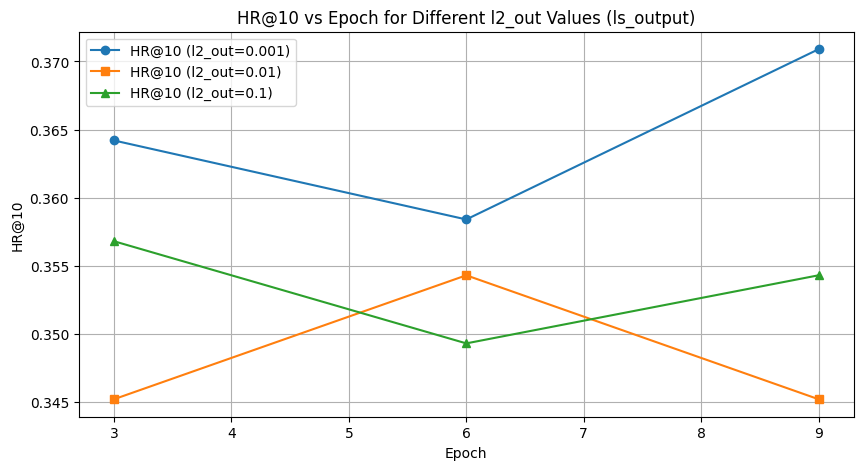

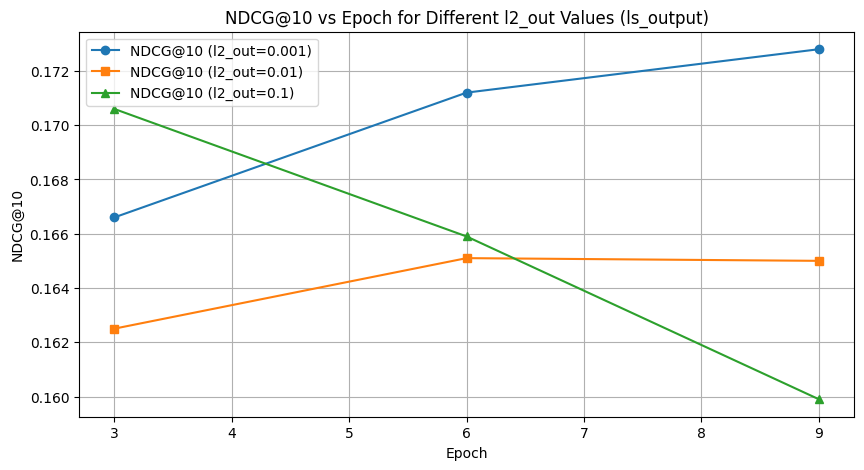

In [2]:
import matplotlib.pyplot as plt
# Validation epochs
val_epochs = [3, 6, 9]

# HR and NDCG for each l2_out
HR_0001 = [0.3642, 0.3584, 0.3709]
NDCG_0001 = [0.1666, 0.1712, 0.1728]

HR_001 = [0.3452, 0.3543, 0.3452]
NDCG_001 = [0.1625, 0.1651, 0.1650]

HR_01 = [0.3568, 0.3493, 0.3543]
NDCG_01 = [0.1706, 0.1659, 0.1599]

# Plot HR@10 vs Epoch
plt.figure(figsize=(10, 5))
plt.plot(val_epochs, HR_0001, marker='o', label='HR@10 (l2_out=0.001)')
plt.plot(val_epochs, HR_001, marker='s', label='HR@10 (l2_out=0.01)')
plt.plot(val_epochs, HR_01, marker='^', label='HR@10 (l2_out=0.1)')
plt.xlabel('Epoch')
plt.ylabel('HR@10')
plt.title('HR@10 vs Epoch for Different l2_out Values (ls_output)')
plt.grid(True)
plt.legend()
plt.show()

# Plot NDCG@10 vs Epoch
plt.figure(figsize=(10, 5))
plt.plot(val_epochs, NDCG_0001, marker='o', label='NDCG@10 (l2_out=0.001)')
plt.plot(val_epochs, NDCG_001, marker='s', label='NDCG@10 (l2_out=0.01)')
plt.plot(val_epochs, NDCG_01, marker='^', label='NDCG@10 (l2_out=0.1)')
plt.xlabel('Epoch')
plt.ylabel('NDCG@10')
plt.title('NDCG@10 vs Epoch for Different l2_out Values (ls_output)')
plt.grid(True)
plt.legend()
plt.show()